## Clase 06

#### Simulación de Procesos Financieros

José Armando Melchor Soto
 | 02/09/2026

---

### Libraries 

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm

---

#### Ejercicio 1 

$k = 100$

$\text{S(T)} = U(50,200)$

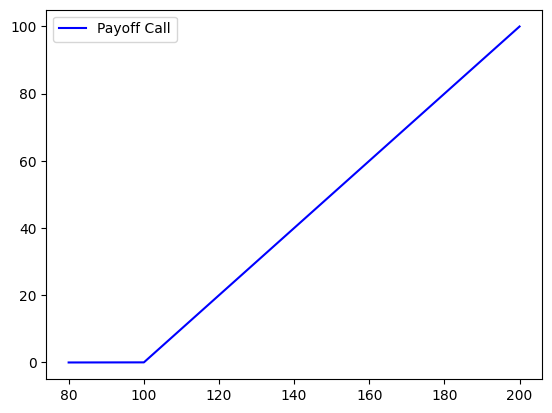

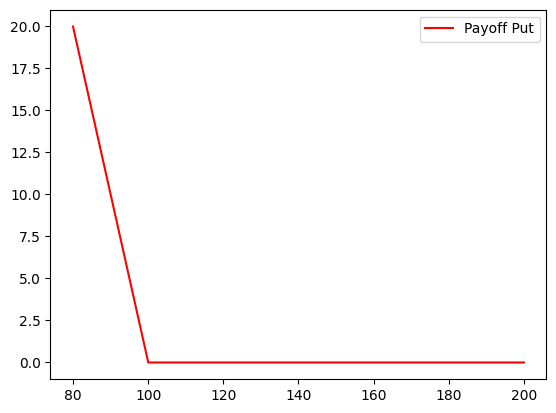

In [48]:

n = 100_000
k = 100

for i in [50,60,70,80]:
    ST = np.random.uniform(i, 200, n)
    
payoff_call = np.maximum(ST - k, 0)
payoff_put  = np.maximum(k - ST, 0)

orden = np.argsort(ST)

plt.plot(ST[orden], payoff_call[orden], label='Payoff Call', color='blue')
plt.legend()
plt.show()

plt.plot(ST[orden], payoff_put[orden],  label='Payoff Put',  color='red')
plt.legend()
plt.show()

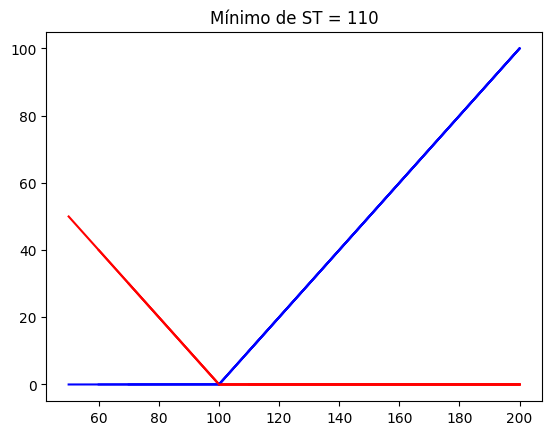

In [4]:

n = 100_000
k = 100

for i in [50, 60, 70, 100, 110]:
    ST = np.random.uniform(i, 200, n)
    payoff_call = np.maximum(ST - k, 0)
    payoff_put  = np.maximum(k - ST, 0)

    orden = np.argsort(ST)

    plt.plot(ST[orden], payoff_call[orden], label='Payoff Call', color='blue')
    plt.plot(ST[orden], payoff_put[orden],  label='Payoff Put',  color='red')
    plt.title(f'Mínimo de ST = {i}')
plt.show()


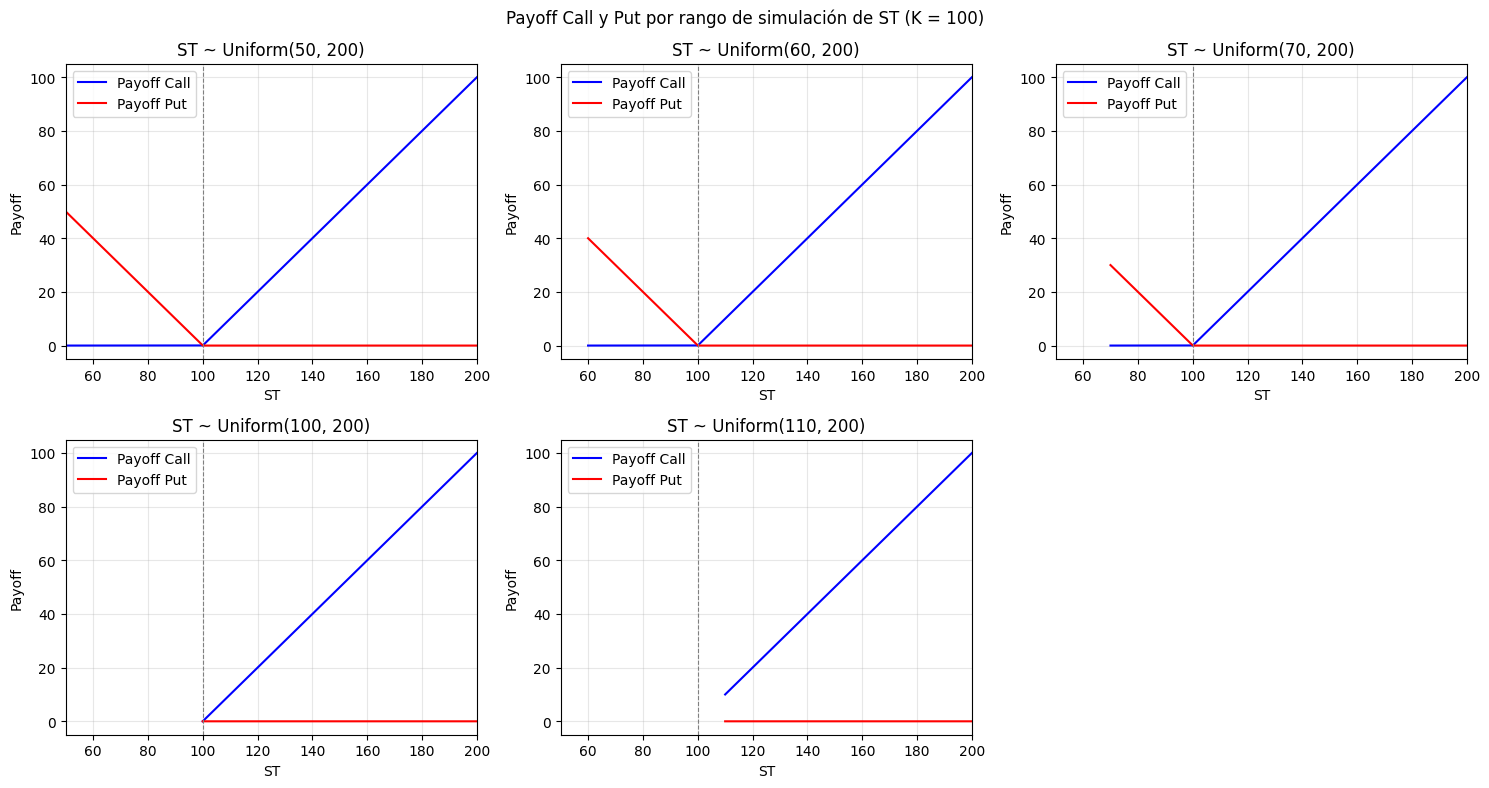

In [5]:

n = 100_000
k = 100
lows = [50, 60, 70, 100, 110]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, i in zip(axes.flat, lows):
    ST = np.random.uniform(i, 200, n)
    payoff_call = np.maximum(ST - k, 0)
    payoff_put  = np.maximum(k - ST, 0)
    orden = np.argsort(ST)

    ax.plot(ST[orden], payoff_call[orden], label='Payoff Call', color='blue')
    ax.plot(ST[orden], payoff_put[orden],  label='Payoff Put',  color='red')
    ax.axvline(k, color='gray', ls='--', lw=0.8)
    ax.set_title(f'ST ~ Uniform({i}, 200)')
    ax.set_xlabel('ST'); ax.set_ylabel('Payoff')
    ax.set_xlim(50, 200); ax.grid(True, alpha=0.3); ax.legend()

axes.flat[-1].axis('off')
fig.suptitle('Payoff Call y Put por rango de simulación de ST (K = 100)')
plt.tight_layout()
plt.show()

# Team put

In [6]:
S0 = 100
k = 100
r = 0.05
sigma = 0.20
T = 1
n = 100_000

C:\Users\ppmel\AppData\Local\Temp\ipykernel_39192\1596494219.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


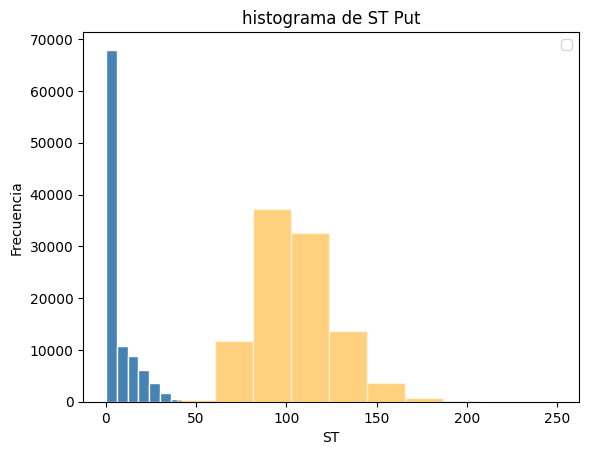

Precio put  = 5.5421


In [22]:
z  = np.random.normal(0, 1, size=n)
ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)

payoff_put  = np.maximum(k - ST, 0)

plt.hist(payoff_put, bins=10, color='steelblue', edgecolor='white')
plt.hist(ST, bins=10, color='orange', edgecolor='white', alpha=0.5)
plt.title('histograma de ST Put')
plt.xlabel('ST'); plt.ylabel('Frecuencia')
plt.legend()
plt.show()


precio_put  = np.exp(-r*T) * payoff_put.mean()
print(f'Precio put  = {precio_put:.4f}')

C:\Users\ppmel\AppData\Local\Temp\ipykernel_39192\2639027212.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


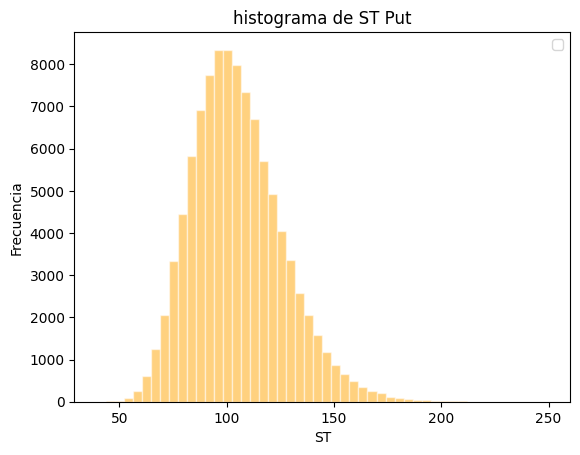

In [23]:
plt.hist(ST, bins=50, color='orange', edgecolor='white', alpha=0.5)
plt.title('histograma de ST Put')
plt.xlabel('ST'); plt.ylabel('Frecuencia')
plt.legend()
plt.show()

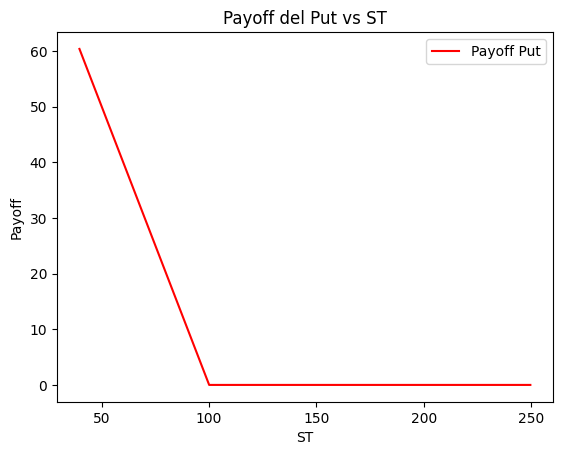

In [31]:

orden = np.argsort(ST)
plt.plot(ST[orden], payoff_put[orden], label='Payoff Put', color='red')
plt.title('Payoff del Put vs ST')
plt.xlabel('ST'); plt.ylabel('Payoff')     
plt.legend()
plt.show()

In [46]:
S0 = 100
k = 100
r = 0.05
T = 1
n = 100_000

volatilidades = [0.10, 0.2, 0.40, 0.5]   

filas = []
for sigma in volatilidades:
    z  = np.random.normal(0, 1, n)
    ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)
    
    payoff_put  = np.maximum(k - ST, 0)

    filas.append({
        'sigma':       sigma,
        'payoff_put':  payoff_put.mean()
    })

tabla = pd.DataFrame(filas)
tabla.round(4)


,sigma,payoff_put
0,0.1,2.0215
1,0.2,5.9098
2,0.4,13.7581
3,0.5,17.6818


In [45]:

rf = [0.05, 0.1, 0.20]   
sigma = 0.2
filas = []

for r in rf:
    z  = np.random.normal(0, 1, n)
    ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)
    
    payoff_put  = np.maximum(k - ST, 0)

    filas.append({
        'r':       r,
        'payoff_put':  payoff_put.mean()
    })

tabla = pd.DataFrame(filas)
tabla.round(4)

,r,payoff_put
0,0.05,5.9048
1,0.10,4.1774
2,0.20,1.8273


In [51]:

Time = [0.25, 0.5, 1, 2]   
sigma = 0.2
S0 = 100
k = 100
r = 0.05
n = 100_000


filas = []

for T in Time:
    z  = np.random.normal(0, 1, n)
    ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)
    
    payoff_put  = np.maximum(k - ST, 0)

    filas.append({
        'T':       T,
        'payoff_put':  payoff_put.mean()
    })

tabla = pd.DataFrame(filas)
tabla.round(4)

,T,payoff_put
0,0.25,3.3913
1,0.50,4.5453
2,1.00,5.8768
3,2.00,7.3816


In [58]:

price = [80,90,100,110,120]   
sigma = 0.2
S0 = 100
r = 0.05
n = 100_000
T = 1

filas = []

for K in price:
    z  = np.random.normal(0, 1, n)
    ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)

    payoff_put  = np.maximum(K - ST, 0)

    filas.append({
        'K':       K,
        'payoff_put':  payoff_put.mean()
    })

tabla = pd.DataFrame(filas)
tabla.round(4)

,K,payoff_put
0,80,0.7254
1,90,2.4166
2,100,5.8272
3,110,11.2458
4,120,18.3512
